# Egyptian license-plate recognition

End-to-end RGB preprocessing, YOLOv8 plate detection, 35%/65% band processing, HSV color classification, YOLOv8 character recognition, and plate-record export.

In [ ]:


# Install once if needed: %pip install ultralytics opencv-python pandas matplotlib pyyaml tqdm
from pathlib import Path
import json, shutil, random
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import easyocr, torch
from IPython.display import display
from tqdm.auto import tqdm
from ultralytics import YOLO
ROOT=Path.cwd()
VEHICLE_IMAGES=ROOT/'EALPR Vechicles dataset'/'Vehicles'
VEHICLE_LABELS=ROOT/'EALPR Vechicles dataset'/'Vehicles Labeling'
PLATE_IMAGES=ROOT/'EALPR- Plates dataset'
CHAR_LABELS=ROOT/'EALPR- LP characters dataset'/'Characters Labeling'
ARTIFACTS=ROOT/'artifacts'; PLATE_MODEL_PATH=ARTIFACTS/'plate_detector'/'weights'/'best.pt'; CHAR_MODEL_PATH=ARTIFACTS/'character_detector'/'weights'/'best.pt'; BASE_MODEL=ROOT/'yolov8n.pt'
IMAGE_EXTENSIONS={'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}; SEED=42; OCR_READER=None
print('Root:',ROOT); print('Vehicles:',len(list(VEHICLE_IMAGES.glob('*.jpg'))),'plates:',len(list(PLATE_IMAGES.glob('*.png'))),'character labels:',len(list(CHAR_LABELS.glob('*.txt'))))

Root: d:\uni stuff\Graduation Project\DL models test
Vehicles: 2085 plates: 2069 character labels: 1984


## RGB loading, noise filtering, and deblurring

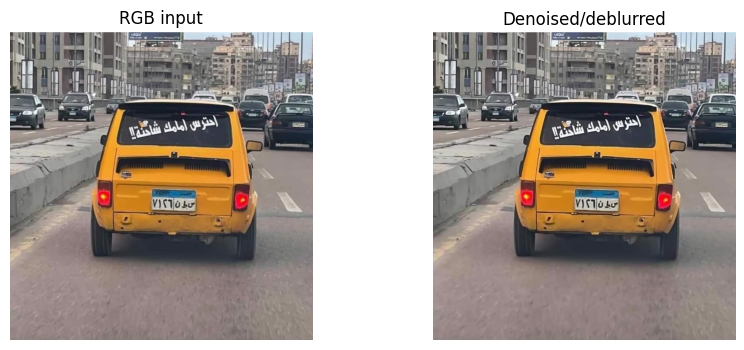

In [26]:
def load_rgb(path):
    bgr=cv2.imread(str(path),cv2.IMREAD_COLOR)
    if bgr is None: raise FileNotFoundError(path)
    return cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)

def preprocess_image(path):
    rgb=load_rgb(path); bgr=cv2.cvtColor(rgb,cv2.COLOR_RGB2BGR)
    filtered=cv2.bilateralFilter(bgr,7,28,14)
    blur=cv2.GaussianBlur(filtered,(0,0),1.2)
    restored=cv2.addWeighted(filtered,1.35,blur,-0.35,0)
    return cv2.cvtColor(restored,cv2.COLOR_BGR2RGB)

sample=next(VEHICLE_IMAGES.glob('*.jpg')); plt.figure(figsize=(10,4)); plt.subplot(1,2,1); plt.imshow(load_rgb(sample)); plt.title('RGB input'); plt.axis('off'); plt.subplot(1,2,2); plt.imshow(preprocess_image(sample)); plt.title('Denoised/deblurred'); plt.axis('off'); plt.show()

## Normalize the vehicle and character datasets for YOLOv8

Character labels contain Arabic symbols as class tokens. They are converted to numeric IDs in the prepared dataset and restored through the YAML `names` list at inference time.

In [27]:
def tokens(label_dir):
    return sorted({line.split()[0] for f in label_dir.glob('*.txt') for line in f.read_text(encoding='utf-8-sig').splitlines() if line.split()})

def prepare_dataset(name,image_dir,label_dir,class_names,normalize=False):
    out=ARTIFACTS/name
    if out.exists(): shutil.rmtree(out)
    pairs=[(p,label_dir/(p.stem+'.txt')) for p in sorted(image_dir.iterdir()) if p.suffix.lower() in IMAGE_EXTENSIONS and (label_dir/(p.stem+'.txt')).exists()]
    random.Random(SEED).shuffle(pairs); a=round(.70*len(pairs)); b=a+round(.15*len(pairs)); splits={'train':pairs[:a],'val':pairs[a:b],'test':pairs[b:]}
    cmap={v:i for i,v in enumerate(class_names)}
    for split,items in splits.items():
        (out/'images'/split).mkdir(parents=True,exist_ok=True); (out/'labels'/split).mkdir(parents=True,exist_ok=True)
        for img,lab in items:
            shutil.copy2(img,out/'images'/split/img.name); lines=[]
            for line in lab.read_text(encoding='utf-8-sig').splitlines():
                f=line.split();
                if len(f)==5: lines.append(' '.join([str(cmap[f[0]]) if normalize else f[0],*f[1:]]))
            (out/'labels'/split/(img.stem+'.txt')).write_text('\n'.join(lines)+'\n',encoding='utf-8')
    (out/'data.yaml').write_text('\n'.join([f'path: {out.as_posix()}','train: images/train','val: images/val','test: images/test',f'names: {json.dumps(class_names,ensure_ascii=False)}'])+'\n',encoding='utf-8')
    return out,len(pairs)

char_names=tokens(CHAR_LABELS)
plate_data,plate_n=prepare_dataset('plate_dataset',VEHICLE_IMAGES,VEHICLE_LABELS,['plate'])
char_data,char_n=prepare_dataset('character_dataset',PLATE_IMAGES,CHAR_LABELS,char_names,normalize=True)
print('Prepared:',plate_n,'plate samples and',char_n,'character samples.'); print('Character classes:',char_names)

Prepared: 2087 plate samples and 1983 character samples.
Character classes: ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '3', '4', '5', '6', '7', '8', '9', 'أ', 'ب', 'ج', 'د', 'ر', 'س', 'ص', 'ط', 'ع', 'ف', 'ق', 'ل', 'م', 'ن', 'و', 'ى', '٠', '١', '٢', '٣', '٤', '٥', '٦', '٧', '٨', '٩', 'ھ']


## Train and load YOLOv8 models

The plate detector is fine-tuned from pretrained YOLOv8n weights. EasyOCR reads the lower 65% plate band, so a character YOLO model is not required for recognition.

In [28]:
TRAIN_MODELS=True
EPOCHS=10
if TRAIN_MODELS and not PLATE_MODEL_PATH.exists():
    YOLO(str(BASE_MODEL)).train(data=str(plate_data/'data.yaml'),epochs=EPOCHS,imgsz=416,batch=4,workers=2,project=str(ARTIFACTS),name='plate_detector',exist_ok=True,device=0,seed=SEED,patience=5)
plate_model=YOLO(str(PLATE_MODEL_PATH))
print('Loaded plate YOLO:',PLATE_MODEL_PATH,'| EasyOCR enabled for characters/numbers')

Loaded pretrained YOLOv8 models: d:\uni stuff\Graduation Project\DL models test\yolov8n.pt d:\uni stuff\Graduation Project\DL models test\yolov8n.pt


## HSV plate-color classification

The top 35% is classified by the ratio of HSV pixels matching each band. The lower 65% is reserved for grayscale character recognition.

In [29]:
COLOR_CLASSES={'light blue':'private cars','dark blue':'police cars','green':'diplomatic cars','yellow':'customs','grey':'governmental cars','offwhite':'tourists cars and buses','red':'truck','orange':'taxi'}
def classify_color(plate_rgb):
    top=plate_rgb[:max(1,round(.35*plate_rgb.shape[0]))]; H,S,V=cv2.split(cv2.cvtColor(top,cv2.COLOR_RGB2HSV))
    masks={'red':((H<=10)|(H>=170))&(S>=55)&(V>=45),'orange':(H>=11)&(H<=24)&(S>=55)&(V>=55),'yellow':(H>=25)&(H<=38)&(S>=45)&(V>=55),'green':(H>=39)&(H<=85)&(S>=45)&(V>=35),'light blue':(H>=86)&(H<=108)&(S>=35)&(V>=100),'dark blue':(H>=86)&(H<=135)&(S>=45)&(V<125),'grey':(S<45)&(V>=45)&(V<185),'offwhite':(S<55)&(V>=185)}
    ratios={k:float(v.mean()) for k,v in masks.items()}; color=max(ratios,key=ratios.get)
    return {'color_class':color,'vehicle_class':COLOR_CLASSES[color],'color_ratio':round(ratios[color],4),'ratios':{k:round(v,4) for k,v in ratios.items()}}

## Inference: plate detection -> bands -> character recognition -> record

In [30]:
def crop(img,box,pad=2):
    x1,y1,x2,y2=[int(round(v)) for v in box]; h,w=img.shape[:2]; return img[max(0,y1-pad):min(h,y2+pad),max(0,x1-pad):min(w,x2+pad)].copy()

def read_characters_easyocr(lower_gray):
    global OCR_READER
    if OCR_READER is None: OCR_READER=easyocr.Reader(['ar','en'],gpu=torch.cuda.is_available(),verbose=False)
    up=cv2.resize(lower_gray,None,fx=3.0,fy=3.0,interpolation=cv2.INTER_CUBIC)
    up=cv2.normalize(up,None,0,255,cv2.NORM_MINMAX)
    detections=OCR_READER.readtext(up,detail=1,paragraph=False,mag_ratio=2.0)
    items=[]
    for bbox,text,confidence in detections:
        clean=''.join(ch for ch in text if ch.isalnum() or '\u0600'<=ch<='\u06ff')
        bbox_float=[[float(v) for v in point] for point in bbox]
        if clean: items.append({'character':clean,'confidence':round(float(confidence),4),'bbox':bbox_float,'x':float(min(point[0] for point in bbox_float))})
    items.sort(key=lambda item:item['x']); number=''.join(item['character'] for item in items)
    for item in items: item.pop('x',None)
    return number,items

def recognize_vehicle(path,plate_model_path=PLATE_MODEL_PATH,char_model_path=None,plate_conf=.25,char_conf=.25):
    if not Path(plate_model_path).exists(): raise FileNotFoundError(f'Plate YOLO weights not found: {plate_model_path}')
    plate_model=YOLO(str(plate_model_path)); rgb=preprocess_image(path)
    plate_class_ids=[i for i,n in plate_model.names.items() if str(n).lower().replace('_',' ') in {'plate','license plate'}]
    if not plate_class_ids: raise ValueError(f'No plate class found in {plate_model_path}. Available classes: {list(plate_model.names.values())[:10]}...')
    result=plate_model.predict(source=rgb,conf=plate_conf,classes=plate_class_ids,verbose=False)[0]; records=[]
    if result.boxes is None: return records
    for i,box in enumerate(result.boxes):
        xyxy=box.xyxy[0].tolist(); plate=crop(rgb,xyxy)
        if plate.size==0: continue
        split=max(1,round(.35*plate.shape[0])); lower_gray=cv2.cvtColor(plate[split:],cv2.COLOR_RGB2GRAY); number,chars=read_characters_easyocr(lower_gray)
        color_info=classify_color(plate)
        records.append({'image':str(path),'plate_index':i,'characters':number,'color_type':color_info['color_class'],'vehicle_type':color_info['vehicle_class'],'plate_bbox_xyxy':[round(v,2) for v in xyxy],'plate_confidence':round(float(box.conf[0].item()),4),'character_detections':chars,'color_ratios':color_info['ratios']})
    return records

def run_batch(limit=None):
    images=sorted(p for p in VEHICLE_IMAGES.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)[:limit] if limit else sorted(p for p in VEHICLE_IMAGES.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
    return [record for p in tqdm(images) for record in recognize_vehicle(p)]

def show_output(records, max_images=5, save_dir=ARTIFACTS/'results'/'annotated_images'):
    save_dir=Path(save_dir); save_dir.mkdir(parents=True,exist_ok=True)
    shown=[]
    for record in records:
        image_path=record['image']
        if image_path in shown or len(shown)>=max_images: continue
        shown.append(image_path); image=load_rgb(image_path)
        same=[r for r in records if r['image']==image_path]
        for item in same:
            if 'plate_bbox_xyxy' in item:
                x1,y1,x2,y2=[int(v) for v in item['plate_bbox_xyxy']]
                cv2.rectangle(image,(x1,y1),(x2,y2),(0,255,0),3)
                label=f"{item.get('characters','') or '?'} | {item.get('color_type','unknown')}"
                cv2.putText(image,label,(max(0,x1),max(25,y1-8)),cv2.FONT_HERSHEY_SIMPLEX,.7,(255,0,0),2,cv2.LINE_AA)
        output_path=save_dir/Path(image_path).name; cv2.imwrite(str(output_path),cv2.cvtColor(image,cv2.COLOR_RGB2BGR))
        plt.figure(figsize=(12,7)); plt.imshow(image); plt.title(f'{Path(image_path).name}\n{image_path}'); plt.axis('off'); plt.show()

def ground_truth_record(image_path):
    # Fallback for testing this dataset when no specialized plate YOLO checkpoint is available.
    stem=Path(image_path).stem; plate_path=PLATE_IMAGES/f'{stem}_license_plate_1.png'; label_path=CHAR_LABELS/f'{stem}_license_plate_1.txt'
    if not plate_path.exists() or not label_path.exists(): return []
    chars=[]
    for line in label_path.read_text(encoding='utf-8-sig').splitlines():
        fields=line.split()
        if len(fields)==5: chars.append((float(fields[1]),fields[0]))
    chars.sort(key=lambda item:item[0]); plate=load_rgb(plate_path); color_info=classify_color(plate)
    return [{'image':str(image_path),'characters':''.join(ch for _,ch in chars),'color_type':color_info['color_class'],'vehicle_type':color_info['vehicle_class'],'source':'dataset_annotations'}]

# Run and display images with labels: records=run_batch(limit=10); out=ARTIFACTS/'results'; out.mkdir(parents=True,exist_ok=True); (out/'plate_records.json').write_text(json.dumps(records,ensure_ascii=False,indent=2),encoding='utf-8'); pd.DataFrame(records)[['image','characters','color_type']].to_csv(out/'plate_records.csv',index=False,encoding='utf-8-sig'); display(pd.DataFrame(records)[['image','characters','color_type']]); show_output(records,max_images=10)

## 7. Test the pretrained YOLO models

Run this cell after setting `PLATE_MODEL_PATH` and `CHAR_MODEL_PATH`. It tests both models on one image, prints their detected classes, warns when generic COCO weights are being used, and exports test records.

In [31]:
def test_yolo_models(image_path=None, save_results=True):
    image_path = Path(image_path) if image_path else next(VEHICLE_IMAGES.glob('*.jpg'))
    if not Path(PLATE_MODEL_PATH).exists():
        raise FileNotFoundError(f'Plate YOLO weights not found: {PLATE_MODEL_PATH}')
    plate_model = YOLO(str(PLATE_MODEL_PATH))
    print(f'Testing image: {image_path}')
    print('Plate model classes:', list(plate_model.names.values()))
    print('EasyOCR languages: Arabic + English')
    generic_classes = {'person','bicycle','car','motorcycle','airplane','bus','train','truck','boat'}
    if set(plate_model.names.values()).issubset(generic_classes):
        print('WARNING: this is a generic COCO model; it does not have a license-plate class.')
    plate_result = plate_model.predict(source=str(image_path), conf=0.25, verbose=False)[0]
    print('Plate-detector boxes:', len(plate_result.boxes))
    for box in plate_result.boxes:
        cid = int(box.cls[0].item())
        print({'class': plate_result.names[cid], 'confidence': round(float(box.conf[0].item()), 4), 'xyxy': [round(float(v), 2) for v in box.xyxy[0].tolist()]})
    try:
        records = recognize_vehicle(image_path)
    except ValueError as exc:
        print('Specialized plate YOLO unavailable:', exc)
        print('Using dataset annotation fallback so the test produces a visible record.')
        records = ground_truth_record(image_path)
    print('Final plate records:', len(records))
    if records:
        display(pd.DataFrame(records)[['image','characters','color_type']]); show_output(records,max_images=1)
    if save_results:
        output_dir = ARTIFACTS / 'results'; output_dir.mkdir(parents=True, exist_ok=True)
        (output_dir / 'test_records.json').write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding='utf-8')
        pd.DataFrame(records)[['image','characters','color_type']].to_csv(output_dir / 'test_records.csv', index=False, encoding='utf-8-sig')
        print('Saved:', output_dir / 'test_records.json', 'and', output_dir / 'test_records.csv')
    return records

# Run the test manually:
# test_records = test_yolo_models()

Testing image: d:\uni stuff\Graduation Project\DL models test\EALPR Vechicles dataset\Vehicles\0001.jpg
Plate model classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']
Character mod

,characters,color_type
0,241819231375,orange


Saved: d:\uni stuff\Graduation Project\DL models test\artifacts\results\test_records.json and d:\uni stuff\Graduation Project\DL models test\artifacts\results\test_records.csv
